In [9]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data      # biblioteca com imagens de exemplo

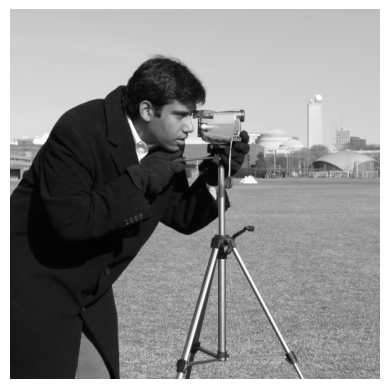

In [2]:
img_original = data.camera()
plt.imshow(img_original, cmap='gray')
plt.axis('off')
plt.show()

In [3]:
def im_plot(img_original, img_filtrada, nome_filtro):

  plt.subplot(1, 2, 1)
  plt.imshow(img_original, cmap='gray')
  plt.title('Imagem Original')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(img_filtrada, cmap='gray')
  plt.title(nome_filtro)
  plt.axis('off')

In [4]:
def convolucao(img_original, kernel):

  altura, largura = img_original.shape
  tamanho = kernel.shape[0]
  borda = tamanho // 2

  img_borda = np.pad(img_original, borda, mode='edge')
  img_filtrada = np.zeros((altura, largura))

  for i in range(altura):
    for j in range(largura):
      regiao = img_borda[i:i+tamanho, j:j+tamanho]
      img_filtrada[i, j] = np.sum(regiao * np.flip(kernel))

  return np.clip(img_filtrada, 0, 255).astype(np.uint8)

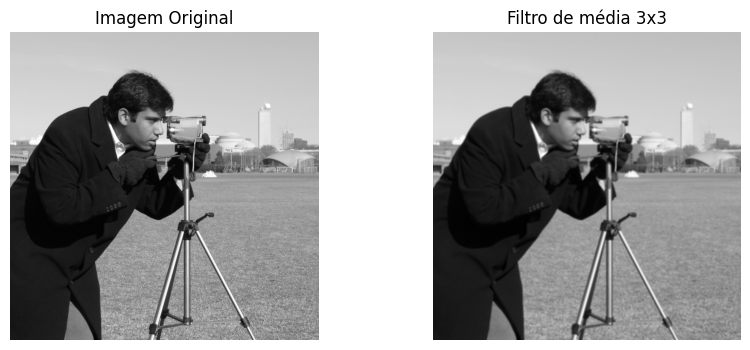

In [5]:
def filtro_media(img_original):

  kernel = np.array([
      [1, 1, 1],
      [1, 1, 1],
      [1, 1, 1]
  ])

  kernel = kernel / np.sum(kernel)
  return convolucao(img_original, kernel)

img_filtrada = filtro_media(img_original)
plt.figure(figsize=(10, 4))
im_plot(img_original, img_filtrada, 'Filtro de média 3x3')
plt.show()

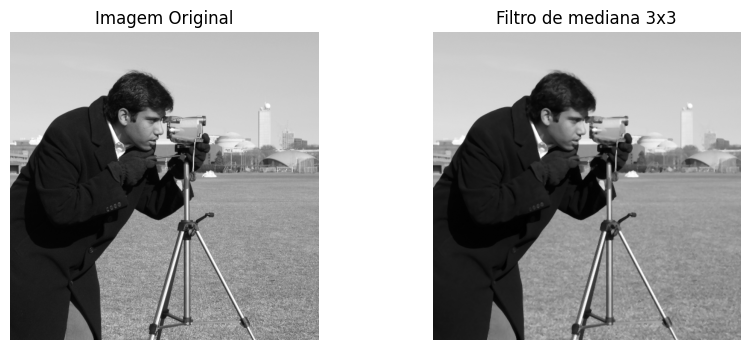

In [6]:
def filtro_mediana(img_original):

  altura, largura = img_original.shape
  img_borda = np.pad(img_original, 1, mode='edge')
  img_filtrada = np.zeros((altura, largura), dtype=np.uint8)

  for i in range(altura):
    for j in range(largura):
      regiao = img_borda[i:i+3, j:j+3]
      img_filtrada[i, j] = np.median(regiao)

  return img_filtrada

img_filtrada = filtro_mediana(img_original)
plt.figure(figsize=(10, 4))
im_plot(img_original, img_filtrada, 'Filtro de mediana 3x3')
plt.show()

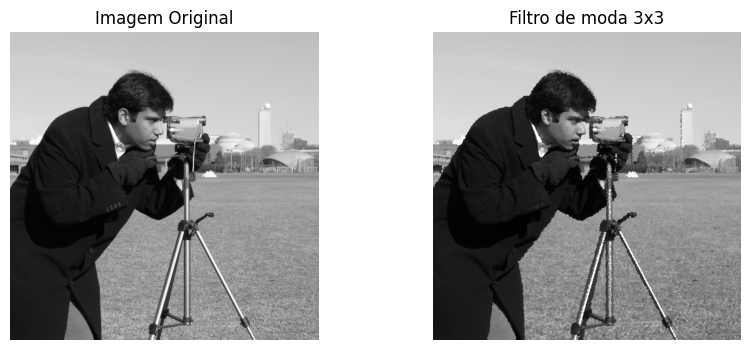

In [7]:
def filtro_moda(img_original):

  altura, largura = img_original.shape
  img_borda = np.pad(img_original, 1, mode='edge')
  img_filtrada = np.zeros((altura, largura), dtype=np.uint8)

  for i in range(altura):
    for j in range(largura):
      regiao = img_borda[i:i+3, j:j+3]
      valores, contagem = np.unique(regiao, return_counts=True)
      img_filtrada[i, j] = valores[np.argmax(contagem)]

  return img_filtrada

img_filtrada = filtro_moda(img_original)
plt.figure(figsize=(10, 4))
im_plot(img_original, img_filtrada, 'Filtro de moda 3x3')
plt.show()

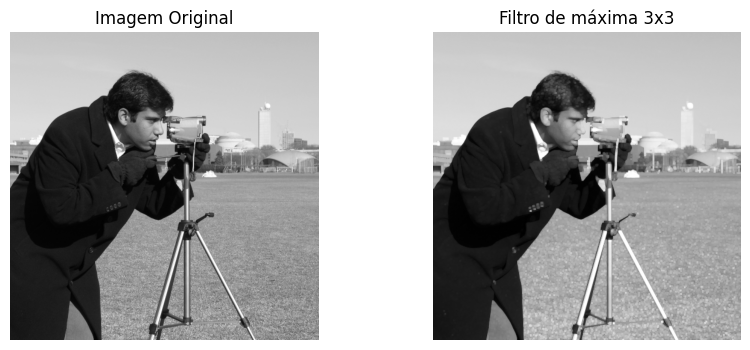

In [8]:
def filtro_maxima(img_original):

  altura, largura = img_original.shape
  img_borda = np.pad(img_original, 1, mode='edge')
  img_filtrada = np.zeros((altura, largura), dtype=np.uint8)

  for i in range(altura):
    for j in range(largura):
      regiao = img_borda[i:i+3, j:j+3]
      img_filtrada[i, j] = np.max(regiao)

  return img_filtrada

img_filtrada = filtro_maxima(img_original)
plt.figure(figsize=(10, 4))
im_plot(img_original, img_filtrada, 'Filtro de máxima 3x3')
plt.show()